In [1]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [2]:
wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

print("Дані успішно завантажено, відмасштабовано та розділено.")
print(f"Розмір навчальної вибірки: {X_train.shape}")
print(f"Розмір тестової вибірки: {X_test.shape}")

Дані успішно завантажено, відмасштабовано та розділено.
Розмір навчальної вибірки: (142, 13)
Розмір тестової вибірки: (36, 13)


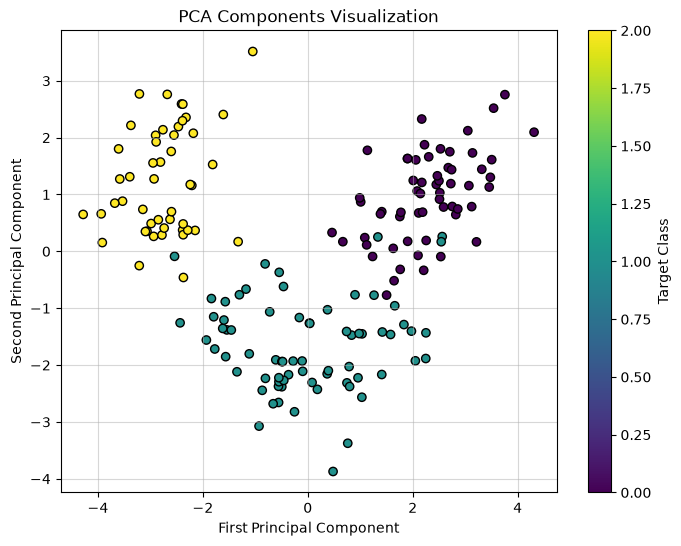

In [3]:
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca_2[:, 0], X_pca_2[:, 1], c=y, cmap='viridis', edgecolor='k')

plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('PCA Components Visualization')

plt.colorbar(scatter, label='Target Class')
plt.grid(True, alpha=0.5)
plt.show()

In [4]:
components_list = [2, 5, 10]
accuracies = []

print("Результати класифікації (Logistic Regression):")
print("-" * 45)

for n in components_list:
    pca = PCA(n_components=n)

    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    model = LogisticRegression(random_state=42)
    model.fit(X_train_pca, y_train)

    y_pred = model.predict(X_test_pca)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)

    print(f"Кількість компонент PCA: {n:<2} | Accuracy: {acc:.4f}")

Результати класифікації (Logistic Regression):
---------------------------------------------
Кількість компонент PCA: 2  | Accuracy: 1.0000
Кількість компонент PCA: 5  | Accuracy: 1.0000
Кількість компонент PCA: 10 | Accuracy: 1.0000



Графік успішно збережено у файл: pca_accuracy_results.png


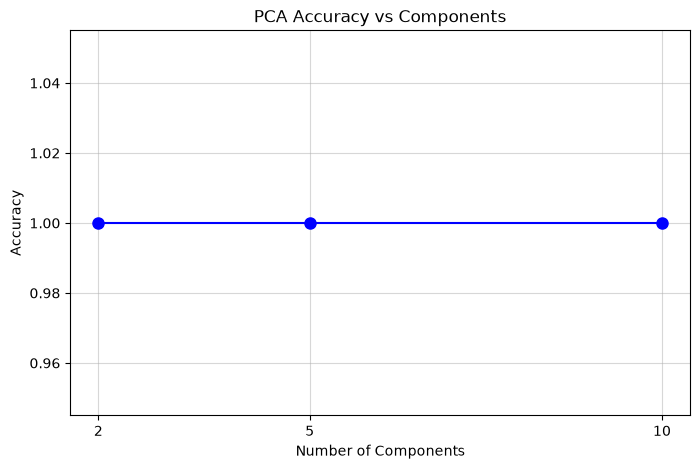

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(components_list, accuracies, marker='o', linestyle='-', color='b', markersize=8)

plt.xlabel('Number of Components')
plt.ylabel('Accuracy')
plt.title('PCA Accuracy vs Components')
plt.xticks(components_list) 
plt.grid(True, alpha=0.5)

save_path = 'pca_accuracy_results.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"\nГрафік успішно збережено у файл: {save_path}")

plt.show()